In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, kurtosis
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.utils.class_weight import compute_class_weight, compute_sample_weight




In [2]:
df = pd.read_csv('dataset/short_form_brain_rot_cognitive_decay.csv')


df.head()

,participant_id,age,gender,primary_platform,daily_short_form_hours,avg_clip_duration_sec,swipes_per_minute,scroll_sessions_day,bedtime_scroll_min,total_sleep_hours,multitasking_score,total_screen_time_hours,sustained_attention_span_sec,working_memory_score,task_switch_latency_sec,brain_fog_score,dopamine_burnout_index,attention_retention_pct,cognitive_decay_tier
0,ROT-00001,24,Female,Instagram Reels,2.4,5.1,11.8,9,70,7.8,4.0,5.9,74.1,7.4,11.1,3.6,37.6,49.4,Mild Attentional Strain
1,ROT-00002,48,Female,TikTok,4.0,11.1,5.4,10,90,6.1,2.9,6.8,71.6,6.9,9.6,4.8,34.7,47.7,Mild Attentional Strain
2,ROT-00003,34,Female,Instagram Reels,3.3,17.5,3.4,13,59,6.5,3.3,8.1,93.8,6.6,8.3,4.4,35.5,62.5,Mild Attentional Strain
3,ROT-00004,30,Male,Instagram Reels,3.6,11.8,5.1,7,57,6.9,2.2,7.3,84.5,6.7,8.8,4.4,36.0,56.3,Mild Attentional Strain
4,ROT-00005,19,Female,YouTube Shorts,1.9,17.3,3.5,4,30,7.2,3.5,6.2,110.2,9.3,7.1,3.8,18.0,73.5,Normal / Intact Focus


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9000 entries, 0 to 8999
Data columns (total 19 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   participant_id                9000 non-null   str    
 1   age                           9000 non-null   int64  
 2   gender                        9000 non-null   str    
 3   primary_platform              9000 non-null   str    
 4   daily_short_form_hours        9000 non-null   float64
 5   avg_clip_duration_sec         9000 non-null   float64
 6   swipes_per_minute             9000 non-null   float64
 7   scroll_sessions_day           9000 non-null   int64  
 8   bedtime_scroll_min            9000 non-null   int64  
 9   total_sleep_hours             9000 non-null   float64
 10  multitasking_score            9000 non-null   float64
 11  total_screen_time_hours       9000 non-null   float64
 12  sustained_attention_span_sec  9000 non-null   float64
 13  working_memory

In [4]:
df.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
age,9000.0,28.697111,9.499582,16.0,21.000,27.0,35.0,55.0
daily_short_form_hours,9000.0,3.203222,1.905133,0.3,1.800,2.8,4.2,10.5
avg_clip_duration_sec,9000.0,11.499200,4.584142,3.0,8.200,11.4,14.5,28.8
swipes_per_minute,9000.0,6.482189,3.766278,2.1,4.100,5.3,7.3,20.0
scroll_sessions_day,9000.0,8.999889,5.549773,1.0,5.000,8.0,12.0,28.0
bedtime_scroll_min,9000.0,59.217667,36.631353,0.0,33.000,53.0,79.0,180.0
total_sleep_hours,9000.0,7.127800,0.930720,3.5,6.500,7.2,7.8,9.5
multitasking_score,9000.0,3.341967,1.944690,1.0,1.700,3.1,4.5,10.0
total_screen_time_hours,9000.0,6.956444,2.034408,2.9,5.500,6.6,8.1,15.5
sustained_attention_span_sec,9000.0,84.859000,31.790705,8.0,67.875,91.7,108.9,153.5


In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
print(f"Dataset berhasil dimuat: {df.shape[0]} baris x {df.shape[1]} kolom\n")

Dataset berhasil dimuat: 9000 baris x 19 kolom



In [8]:
# Tabel Struktur Atribut, Tipe Data, Nilai Hilang, Nilai Unik, Dan Peran Variabel
peran_map = {
    'participant_id': 'Identitas Unik Partisipan (Dibuang di Bab 3)',
    'age': 'Fitur Prediktor Demografi (X1)',
    'gender': 'Fitur Prediktor Demografi (X2)',
    'primary_platform': 'Fitur Prediktor Platform (X3)',
    'daily_short_form_hours': 'Fitur Prediktor Perilaku Layar (X4)',
    'avg_clip_duration_sec': 'Fitur Prediktor Perilaku Layar (X5)',
    'swipes_per_minute': 'Fitur Prediktor Perilaku Layar (X6)',
    'scroll_sessions_day': 'Fitur Prediktor Perilaku Layar (X7)',
    'bedtime_scroll_min': 'Fitur Prediktor Perilaku Tidur (X8)',
    'total_sleep_hours': 'Fitur Prediktor Perilaku Tidur (X9)',
    'multitasking_score': 'Fitur Prediktor Perilaku Kognitif (X10)',
    'total_screen_time_hours': 'Fitur Prediktor Perilaku Layar (X11)',
    'sustained_attention_span_sec': 'Skor Klinis Kognitif (Target Leakage - Dibuang)',
    'working_memory_score': 'Skor Klinis Kognitif (Target Leakage - Dibuang)',
    'task_switch_latency_sec': 'Skor Klinis Kognitif (Target Leakage - Dibuang)',
    'brain_fog_score': 'Skor Klinis Kognitif (Target Leakage - Dibuang)',
    'dopamine_burnout_index': 'Skor Klinis Kognitif (Target Leakage - Dibuang)',
    'attention_retention_pct': 'Skor Klinis Kognitif (Multikolinearitas r=1.0 - Dibuang)',
    'cognitive_decay_tier': 'Variabel Target Klasifikasi (y)'
}

tabel_2_1 = pd.DataFrame({
    'No': range(1, len(df.columns) + 1),
    'Nama Atribut': df.columns,
    'Tipe Data': df.dtypes.astype(str).values,
    'Non-Null': df.notnull().sum().values,
    'Missing': df.isnull().sum().values,
    'Unik': df.nunique().values,
    'Peran Variabel': [peran_map[col] for col in df.columns]
})
print("=== Tabel: Struktur Atribut, Tipe Data, Nilai Hilang, Nilai Unik, Dan Peran Variabel ===")
print(tabel_2_1.to_string(index=False))


=== Tabel: Struktur Atribut, Tipe Data, Nilai Hilang, Nilai Unik, Dan Peran Variabel ===
 No                 Nama Atribut Tipe Data  Non-Null  Missing  Unik                                           Peran Variabel
  1               participant_id       str      9000        0  9000             Identitas Unik Partisipan (Dibuang di Bab 3)
  2                          age     int64      9000        0    40                           Fitur Prediktor Demografi (X1)
  3                       gender       str      9000        0     3                           Fitur Prediktor Demografi (X2)
  4             primary_platform       str      9000        0     4                            Fitur Prediktor Platform (X3)
  5       daily_short_form_hours   float64      9000        0   103                      Fitur Prediktor Perilaku Layar (X4)
  6        avg_clip_duration_sec   float64      9000        0   227                      Fitur Prediktor Perilaku Layar (X5)
  7            swipes_per_minute   f

In [9]:

# Tabel Statistik Deskriptif, Kemiringan Data, Dan Pencilan (9 Fitur Numerik Perilaku)

behav_num = [
    'age', 'daily_short_form_hours', 'avg_clip_duration_sec', 
    'swipes_per_minute', 'scroll_sessions_day', 'bedtime_scroll_min', 
    'total_sleep_hours', 'multitasking_score', 'total_screen_time_hours'
]

desc = df[behav_num].describe().T[['mean', 'std', 'min', '25%', '50%', '75%', 'max']].round(2)
desc.columns = ['Mean', 'Std.Dev', 'Min', 'Q1 (25%)', 'Median (50%)', 'Q3 (75%)', 'Max']
desc['Skewness'] = df[behav_num].skew().round(2)

outlier_counts, outlier_pcts = [], []
for col in behav_num:
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    out = ((df[col] < (q1 - 1.5 * iqr)) | (df[col] > (q3 + 1.5 * iqr))).sum()
    outlier_counts.append(out)
    outlier_pcts.append(round(out / len(df) * 100, 2))

desc['Outlier (Baris)'] = outlier_counts
desc['Outlier (%)'] = outlier_pcts
tabel_2_2 = desc.reset_index().rename(columns={'index': 'Nama Fitur'})
print("\n=== Tabel: Statistik Deskriptif, Kemiringan Data, Dan Pencilan (9 Fitur Numerik Perilaku) ===")
print(tabel_2_2.to_string(index=False))


=== Tabel: Statistik Deskriptif, Kemiringan Data, Dan Pencilan (9 Fitur Numerik Perilaku) ===
             Nama Fitur  Mean  Std.Dev  Min  Q1 (25%)  Median (50%)  Q3 (75%)   Max  Skewness  Outlier (Baris)  Outlier (%)
                    age 28.70     9.50 16.0      21.0          27.0      35.0  55.0      0.76                0         0.00
 daily_short_form_hours  3.20     1.91  0.3       1.8           2.8       4.2  10.5      1.09              244         2.71
  avg_clip_duration_sec 11.50     4.58  3.0       8.2          11.4      14.5  28.8      0.24               41         0.46
      swipes_per_minute  6.48     3.77  2.1       4.1           5.3       7.3  20.0      2.06              726         8.07
    scroll_sessions_day  9.00     5.55  1.0       5.0           8.0      12.0  28.0      0.94              242         2.69
     bedtime_scroll_min 59.22    36.63  0.0      33.0          53.0      79.0 180.0      0.90              237         2.63
      total_sleep_hours  7.13     0.9

In [10]:
# Tabel Analisis Korelasi 6 Fitur Skor Kognitif (Bukti Kebocoran Target)
cog_num = [
    'sustained_attention_span_sec', 'working_memory_score', 
    'task_switch_latency_sec', 'brain_fog_score', 
    'dopamine_burnout_index', 'attention_retention_pct'
]
desc_cog = df[cog_num].describe().T[['mean', 'std', 'min', '50%', 'max']].round(2)
desc_cog.columns = ['Mean', 'Std.Dev', 'Min', 'Median (50%)', 'Max']
desc_cog['Korelasi dgn dopamine_burnout'] = [round(df[c].corr(df['dopamine_burnout_index']), 4) for c in cog_num]
desc_cog['Korelasi dgn sustained_attention'] = [round(df[c].corr(df['sustained_attention_span_sec']), 4) for c in cog_num]
desc_cog['Status di Bab 3'] = [
    'Dihapus (Target Leakage)',
    'Dihapus (Target Leakage)',
    'Dihapus (Target Leakage)',
    'Dihapus (Target Leakage)',
    'Dihapus (Target Leakage)',
    'Dihapus (Multikolinearitas r=1.0000 & Leakage)'
]
tabel_2_3 = desc_cog.reset_index().rename(columns={'index': 'Fitur Skor Kognitif'})
print("\n=== Tabel Analisis Korelasi 6 Fitur Skor Kognitif (Bukti Kebocoran Target) ===")
print(tabel_2_3.to_string(index=False))


=== Tabel Analisis Korelasi 6 Fitur Skor Kognitif (Bukti Kebocoran Target) ===
         Fitur Skor Kognitif  Mean  Std.Dev  Min  Median (50%)   Max  Korelasi dgn dopamine_burnout  Korelasi dgn sustained_attention                                Status di Bab 3
sustained_attention_span_sec 84.86    31.79  8.0          91.7 153.5                        -0.8700                            1.0000                       Dihapus (Target Leakage)
        working_memory_score  7.32     1.06  1.0           7.5  10.0                        -0.8194                            0.7902                       Dihapus (Target Leakage)
     task_switch_latency_sec  9.41     4.17  2.0           8.5  32.0                         0.8609                           -0.8890                       Dihapus (Target Leakage)
             brain_fog_score  3.74     2.16  1.0           3.3  10.0                         0.8890                           -0.7433                       Dihapus (Target Leakage)
      dopamine_

In [11]:
# Tabel Distribusi Kelas Target (Tingkatan Penurunan Kognitif)
order_tiers = [
    'Normal / Intact Focus',
    'Mild Attentional Strain',
    'Severe Focus Fragmentation',
    'Acute Brain Rot / Executive Burnout'
]
vc = df['cognitive_decay_tier'].value_counts().reindex(order_tiers)
vc_pct = (df['cognitive_decay_tier'].value_counts(normalize=True).reindex(order_tiers) * 100).round(2)

tabel_2_4 = pd.DataFrame({
    'Kode Tier': ['Tier 0 (Sehat)', 'Tier 1 (Ringan)', 'Tier 2 (Parah)', 'Tier 3 (Kritis)'],
    'Kelas Target (cognitive_decay_tier)': order_tiers,
    'Jumlah Partisipan': vc.values,
    'Persentase (%)': vc_pct.values,
    'Status Proporsi': ['Mayoritas Dominan', 'Mayoritas', 'Minoritas Menengah', 'Minoritas Ekstrem (Imbalance)']
})
print("\n=== Tabel Distribusi Kelas Target (Tingkatan Penurunan Kognitif) ===")
print(tabel_2_4.to_string(index=False))


=== Tabel Distribusi Kelas Target (Tingkatan Penurunan Kognitif) ===
      Kode Tier Kelas Target (cognitive_decay_tier)  Jumlah Partisipan  Persentase (%)               Status Proporsi
 Tier 0 (Sehat)               Normal / Intact Focus               3863           42.92             Mayoritas Dominan
Tier 1 (Ringan)             Mild Attentional Strain               3677           40.86                     Mayoritas
 Tier 2 (Parah)          Severe Focus Fragmentation               1355           15.06            Minoritas Menengah
Tier 3 (Kritis) Acute Brain Rot / Executive Burnout                105            1.17 Minoritas Ekstrem (Imbalance)


In [12]:
# Tabel Distribusi Fitur Kategorikal (gender & primary_platform)
cat_rows = []
for col in ['gender', 'primary_platform']:
    counts = df[col].value_counts()
    pcts = (df[col].value_counts(normalize=True) * 100).round(2)
    for k in counts.index:
        cat_rows.append({
            'Nama Fitur': col,
            'Kategori': k,
            'Jumlah Partisipan': counts[k],
            'Persentase (%)': pcts[k]
        })
tabel_2_5 = pd.DataFrame(cat_rows)
print("\n=== Tabel  Distribusi Fitur Kategorikal (gender & primary_platform) ===")
print(tabel_2_5.to_string(index=False))


=== Tabel  Distribusi Fitur Kategorikal (gender & primary_platform) ===
      Nama Fitur           Kategori  Jumlah Partisipan  Persentase (%)
          gender               Male               4395           48.83
          gender             Female               4338           48.20
          gender         Non-Binary                267            2.97
primary_platform             TikTok               3684           40.93
primary_platform    Instagram Reels               3044           33.82
primary_platform     YouTube Shorts               1609           17.88
primary_platform Snapchat Spotlight                663            7.37


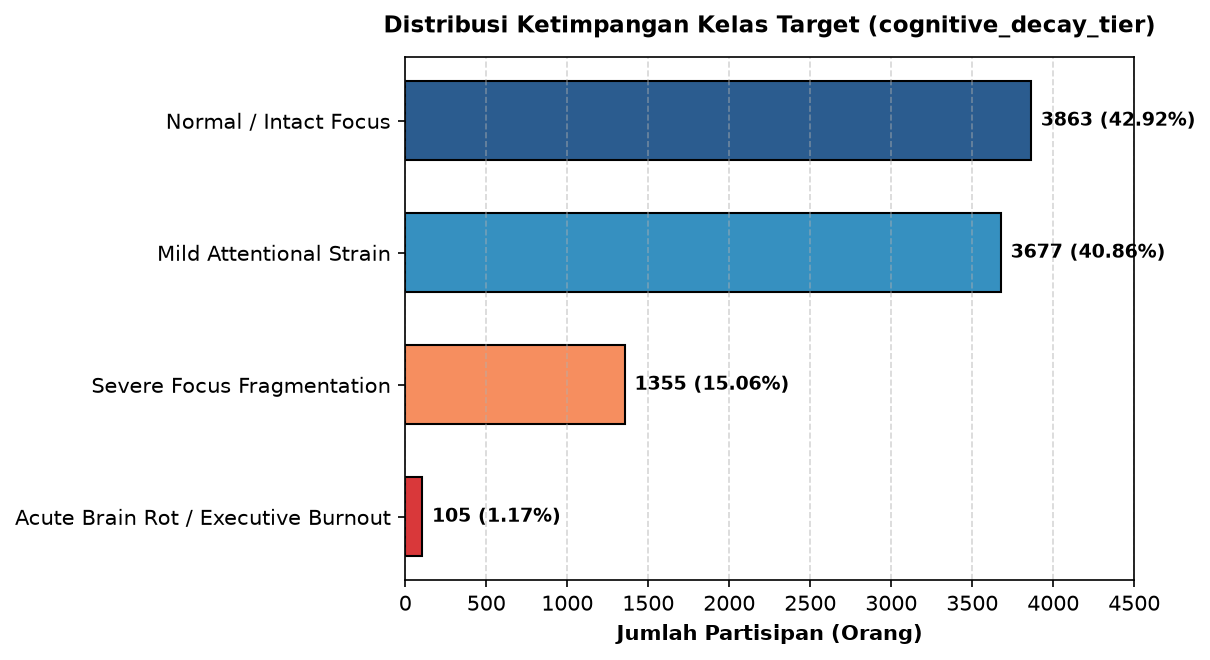

In [13]:
# Gambar Bar Chart Distribusi Kelas Target
colors = ['#2b5c8f', '#3690c0', '#f68e5f', '#d9383a']
fig, ax = plt.subplots(figsize=(8, 4.5), dpi=150)
bars = ax.barh(order_tiers, vc.values, color=colors, edgecolor='black', height=0.6)
ax.invert_yaxis()
ax.set_xlabel('Jumlah Partisipan (Orang)', fontsize=10, fontweight='bold')
ax.set_title('Distribusi Ketimpangan Kelas Target (cognitive_decay_tier)', fontsize=11, fontweight='bold', pad=12)
ax.set_xlim(0, 4500)
for bar, c in zip(bars, vc.values):
    pct = c / len(df) * 100
    ax.text(bar.get_width() + 60, bar.get_y() + bar.get_height()/2, f'{c} ({pct:.2f}%)', 
            va='center', ha='left', fontsize=9, fontweight='bold')
ax.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()



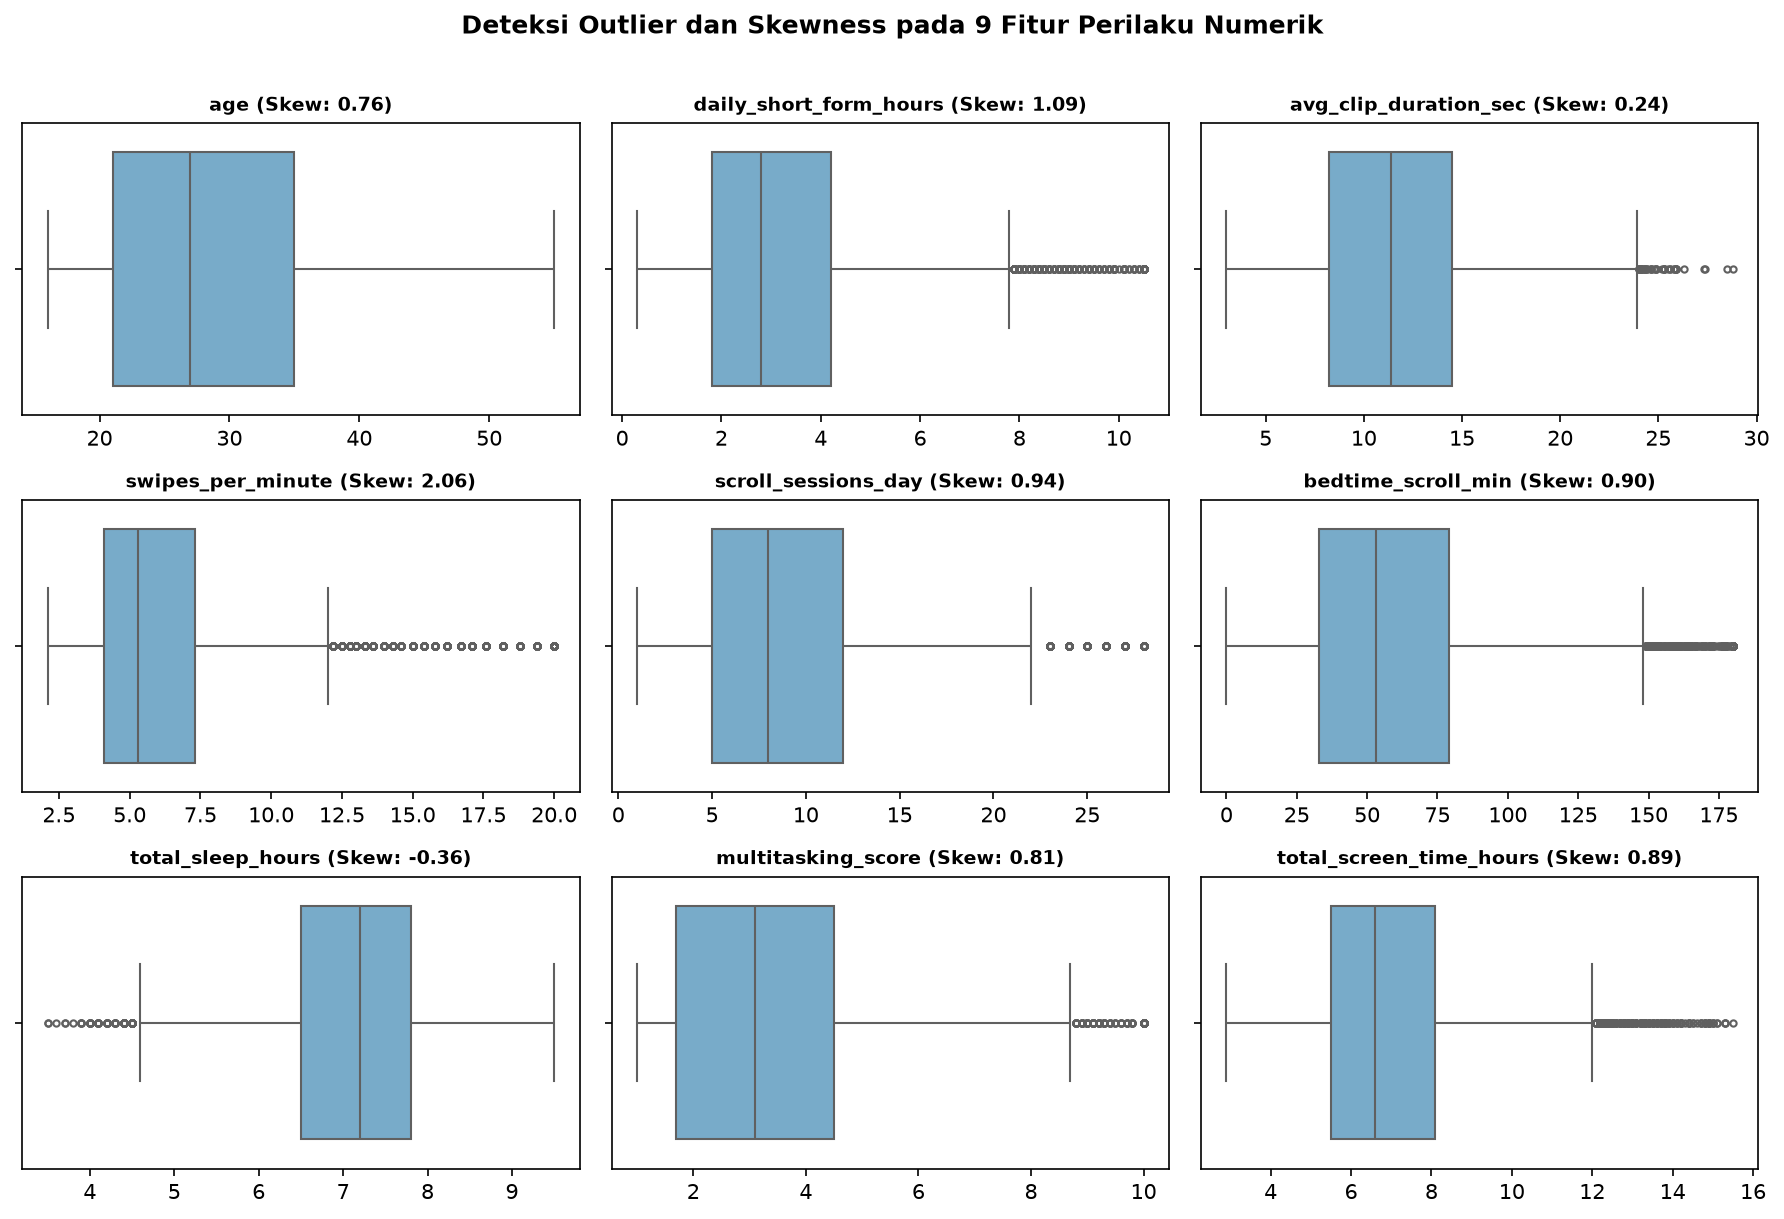

In [14]:
# Gambar Boxplot Outlier 9 Fitur Perilaku
fig, axes = plt.subplots(3, 3, figsize=(12, 8), dpi=150)
axes = axes.flatten()
for i, col in enumerate(behav_num):
    sns.boxplot(x=df[col], ax=axes[i], color='#6baed6', fliersize=3)
    axes[i].set_title(f'{col} (Skew: {df[col].skew():.2f})', fontsize=9, fontweight='bold')
    axes[i].set_xlabel('')
plt.suptitle('Deteksi Outlier dan Skewness pada 9 Fitur Perilaku Numerik', fontsize=12, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

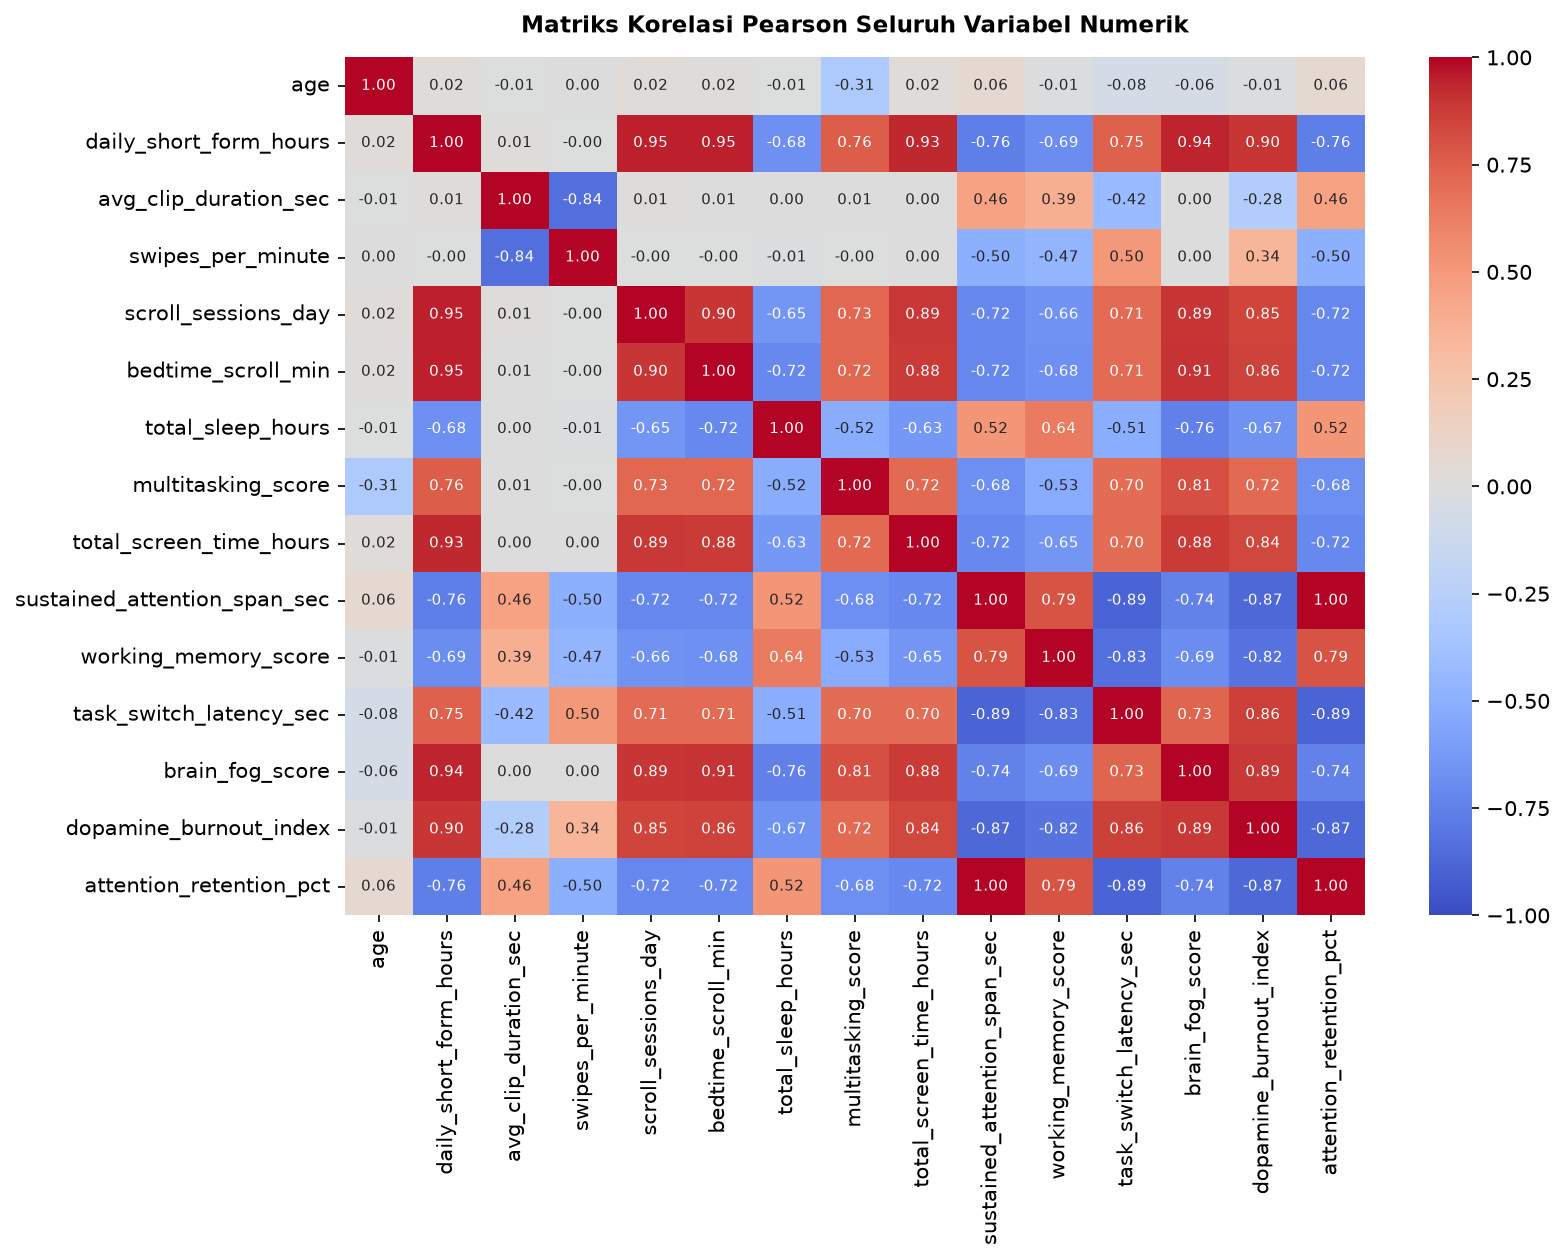

In [15]:
# Gambar Heatmap Korelasi Pearson
num_all = df.select_dtypes(include=[np.number]).columns
fig, ax = plt.subplots(figsize=(11, 8.5), dpi=150)
sns.heatmap(df[num_all].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax, annot_kws={'size': 7})
ax.set_title('Matriks Korelasi Pearson Seluruh Variabel Numerik', fontsize=11, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

In [16]:
# Pemilihat Target dan Fitur
target = 'cognitive_decay_tier'
fitur = [
    'age', 'gender', 'primary_platform', 'daily_short_form_hours',
    'avg_clip_duration_sec', 'swipes_per_minute', 'scroll_sessions_day',
    'bedtime_scroll_min', 'total_sleep_hours', 'multitasking_score',
    'total_screen_time_hours'
]
df = df[fitur + [target]]
df.shape

(9000, 12)

In [17]:
# Split Data (80:20)

X = df[fitur]
y = df[target]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True))

(7200, 11) (1800, 11)
cognitive_decay_tier
Normal / Intact Focus                  0.429167
Mild Attentional Strain                0.408611
Severe Focus Fragmentation             0.150556
Acute Brain Rot / Executive Burnout    0.011667
Name: proportion, dtype: float64


In [18]:

# --- buang Non-Binary ---
df = df[df['gender'] != 'Non-Binary'].copy()

num_cols = ['age', 'daily_short_form_hours', 'avg_clip_duration_sec',
            'swipes_per_minute', 'scroll_sessions_day', 'bedtime_scroll_min',
            'total_sleep_hours', 'multitasking_score', 'total_screen_time_hours']
cat_cols = ['gender', 'primary_platform']

In [19]:
# --- split ulang (data tanpa Non-Binary) ---
X = df[fitur]
y = df[target]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
X_train, X_test = X_train.copy(), X_test.copy()
print(f"Total Data Bersih : {len(df)} baris")
print(f"Dimensi Data Train: {X_train.shape[0]} baris x {X_train.shape[1]} kolom")
print(f"Dimensi Data Test : {X_test.shape[0]} baris x {X_test.shape[1]} kolom")

Total Data Bersih : 8733 baris
Dimensi Data Train: 6986 baris x 11 kolom
Dimensi Data Test : 1747 baris x 11 kolom


In [ ]:
# # --- 1. outlier: clip IQR (batas dari train) ---
# for c in num_cols:
#     q1, q3 = X_train[c].quantile([0.25, 0.75])
#     iqr = q3 - q1
#     low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
#     X_train[c] = X_train[c].clip(low, high)
#     X_test[c] = X_test[c].clip(low, high)

In [20]:
# --- 2. encoding target ---
urutan = {'Normal / Intact Focus': 0,
          'Mild Attentional Strain': 1,
          'Severe Focus Fragmentation': 2,
          'Acute Brain Rot / Executive Burnout': 3}
y_train = y_train.map(urutan)
y_test = y_test.map(urutan)

In [21]:
# --- 3. scaling + one-hot ---
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_cols)
])
X_train_final = pd.DataFrame(preprocessor.fit_transform(X_train),
                             columns=preprocessor.get_feature_names_out(), index=X_train.index)
X_test_final = pd.DataFrame(preprocessor.transform(X_test),
                            columns=preprocessor.get_feature_names_out(), index=X_test.index)

print(X_train_final.shape, X_test_final.shape)
print(y_train.value_counts())
print(y_test.value_counts())

(6986, 13) (1747, 13)
cognitive_decay_tier
0    2998
1    2857
2    1049
3      82
Name: count, dtype: int64
cognitive_decay_tier
0    750
1    715
2    262
3     20
Name: count, dtype: int64


In [23]:
tabel_3_1 = pd.DataFrame({
    'Nama Fitur': num_cols,
    'Min (Train Asli)': X_train[num_cols].min().round(2).values,
    'Max (Train Asli)': X_train[num_cols].max().round(2).values,
    'Mean (Sebelum Scale)': X_train[num_cols].mean().round(2).values,
    'Std.Dev (Sebelum Scale)': X_train[num_cols].std().round(2).values,
    'Mean (Sesudah Scale)': X_train_final[[f'num__{c}' for c in num_cols]].mean().round(2).values,
    'Std.Dev (Sesudah Scale)': X_train_final[[f'num__{c}' for c in num_cols]].std().round(2).values
})
print("=== Tabel Statistik Fitur Numerik Sebelum vs Sesudah StandardScaler (Data Latih) ===")
print(tabel_3_1.to_string(index=False))

print("\n5 Baris Pertama X_train_final Setelah Preprocessing:")
display(X_train_final.head())

=== Tabel Statistik Fitur Numerik Sebelum vs Sesudah StandardScaler (Data Latih) ===
             Nama Fitur  Min (Train Asli)  Max (Train Asli)  Mean (Sebelum Scale)  Std.Dev (Sebelum Scale)  Mean (Sesudah Scale)  Std.Dev (Sesudah Scale)
                    age              16.0              55.0                 28.75                     9.50                   0.0                      1.0
 daily_short_form_hours               0.3              10.5                  3.21                     1.92                  -0.0                      1.0
  avg_clip_duration_sec               3.0              28.5                 11.53                     4.57                   0.0                      1.0
      swipes_per_minute               2.1              20.0                  6.44                     3.70                   0.0                      1.0
    scroll_sessions_day               1.0              28.0                  9.00                     5.57                  -0.0                 

,num__age,num__daily_short_form_hours,num__avg_clip_duration_sec,num__swipes_per_minute,num__scroll_sessions_day,num__bedtime_scroll_min,num__total_sleep_hours,num__multitasking_score,num__total_screen_time_hours,cat__gender_Male,cat__primary_platform_Snapchat Spotlight,cat__primary_platform_TikTok,cat__primary_platform_YouTube Shorts
7787,1.710168,0.620424,0.584160,-0.605335,0.897733,0.828987,-1.207802,0.536586,0.409682,0.0,0.0,1.0,0.0
8981,0.236760,0.047575,-0.225373,-0.200173,-0.179362,-0.307788,-0.886732,-0.177382,-0.324839,1.0,0.0,1.0,0.0
4066,-1.026161,-0.889816,0.168454,-0.416259,-1.076941,-0.416053,-0.672686,-1.197337,-1.206264,0.0,0.0,0.0,1.0
2261,0.131517,-1.514742,2.137589,-0.983487,-1.435972,-0.984440,0.611591,-1.197337,-1.402136,1.0,0.0,0.0,1.0
6506,0.762977,0.151729,-0.006580,-0.335227,0.179670,-0.226590,0.183499,0.077606,0.556586,0.0,0.0,1.0,0.0


In [28]:
# 1. Daftar kode kelas target (0, 1, 2, 3)
daftar_kode_kelas = np.array([0, 1, 2, 3])

# 2. Hitung bobot penalti untuk menangani kelas tidak seimbang (imbalance)
daftar_bobot_kelas = compute_class_weight(
    class_weight='balanced',
    classes=daftar_kode_kelas,
    y=y_train
)

# A. Format Kamus Bobot (Dipakai untuk Random Forest)
kamus_bobot_kelas = dict(zip(daftar_kode_kelas, daftar_bobot_kelas.round(4)))

# B. Format Bobot per Sampel (Dipakai untuk XGBoost)
bobot_sampel_latih = compute_sample_weight(
    class_weight='balanced',
    y=y_train
)

# 3. Label deskriptif untuk setiap tingkat kognitif
label_tingkat_kognitif = [
    'Tier 0: Penurunan Nol / Fokus Utuh (Normal)',
    'Tier 1: Penurunan Ringan (Mild Strain)',
    'Tier 2: Penurunan Parah (Severe Fragmentation)',
    'Tier 3: Penurunan Akut (Acute Brain Rot)'
]

# 4. Menyusun DataFrame 
tabel_distribusi_dan_bobot = pd.DataFrame({
    'Kode Kelas': daftar_kode_kelas,
    'Label Tingkat Penurunan Kognitif': label_tingkat_kognitif,
    'Data Latih (80%)': [int((y_train == k).sum()) for k in daftar_kode_kelas],
    'Data Latih (%)': [round((y_train == k).mean() * 100, 2) for k in daftar_kode_kelas],
    'Data Uji (20%)': [int((y_test == k).sum()) for k in daftar_kode_kelas],
    'Data Uji (%)': [round((y_test == k).mean() * 100, 2) for k in daftar_kode_kelas],
    'Bobot Penalti (Weight)': daftar_bobot_kelas.round(4)
})

# 5. Tampilkan tabel ke layar
print("=== Tabel Distribusi Data Split (80:20) dan Bobot Penalti Kelas (Cost-Sensitive) ===")
print(tabel_distribusi_dan_bobot.to_string(index=False))

=== Tabel Distribusi Data Split (80:20) dan Bobot Penalti Kelas (Cost-Sensitive) ===
 Kode Kelas               Label Tingkat Penurunan Kognitif  Data Latih (80%)  Data Latih (%)  Data Uji (20%)  Data Uji (%)  Bobot Penalti (Weight)
          0    Tier 0: Penurunan Nol / Fokus Utuh (Normal)              2998           42.91             750         42.93                  0.5826
          1         Tier 1: Penurunan Ringan (Mild Strain)              2857           40.90             715         40.93                  0.6113
          2 Tier 2: Penurunan Parah (Severe Fragmentation)              1049           15.02             262         15.00                  1.6649
          3       Tier 3: Penurunan Akut (Acute Brain Rot)                82            1.17              20          1.14                 21.2988
